In [1]:
import numpy as np

In [2]:
!pip install -e . --user

Obtaining file:///eos/home-i00/t/tprebiba/Shared/SPS-supercycles_forNikos
  Preparing metadata (setup.py) ... done
  Running setup.py develop for supercycles


In [3]:
from supercycles.database import SPSCYCLES, PSCYCLES
from supercycles.supercycle import Supercycle

# Check length of basic supercycles

In [17]:
physics_supercycle = Supercycle('SPS', 'Physics',
                                [SPSCYCLES['SFTPRO'], SPSCYCLES['deGauss'], SPSCYCLES['SFTPRO'], SPSCYCLES['deGauss']])

print('Length of the supercycle (s): ', physics_supercycle.length, 'or ', physics_supercycle.bps, 'basic periods')
print('It consists of these cycles: ', physics_supercycle.cycle_names)
print('Each cycle has the following lengths: ')
for cycle in physics_supercycle.cycles:
    print(cycle.name, cycle.length, 'seconds or', cycle.bps, 'basic periods')

Length of the supercycle (s):  28.799999999999997 or  24 basic periods
It consists of these cycles:  ['SFTPRO', 'deGauss', 'SFTPRO', 'deGauss']
Each cycle has the following lengths: 
SFTPRO 10.799999999999999 seconds or 9 basic periods
deGauss 3.5999999999999996 seconds or 3 basic periods
SFTPRO 10.799999999999999 seconds or 9 basic periods
deGauss 3.5999999999999996 seconds or 3 basic periods


In [18]:
hiradmat_supercycle = Supercycle('SPS', 'Hiradmat',
                                 [SPSCYCLES['SFTPRO'], SPSCYCLES['deGauss'], SPSCYCLES['HiRadMat']])
print('Length of the supercycle (s): ', hiradmat_supercycle.length, 'or ', hiradmat_supercycle.bps, 'basic periods')
print('It consists of these cycles: ', hiradmat_supercycle.cycle_names)
print('Each cycle has the following lengths: ')
for cycle in hiradmat_supercycle.cycles:
    print(cycle.name, cycle.length, 'seconds or', cycle.bps, 'basic periods')

Length of the supercycle (s):  38.4 or  32 basic periods
It consists of these cycles:  ['SFTPRO', 'deGauss', 'HiRadMat']
Each cycle has the following lengths: 
SFTPRO 10.799999999999999 seconds or 9 basic periods
deGauss 3.5999999999999996 seconds or 3 basic periods
HiRadMat 24.0 seconds or 20 basic periods


In [19]:
another_hiradmat_supercycle = Supercycle('SPS', 'Hiradmat',
                                        [SPSCYCLES['SFTPRO'], SPSCYCLES['deGauss'], SPSCYCLES['HiRadMat'], SPSCYCLES['SFTPRO'], SPSCYCLES['deGauss']])
print('Length of the supercycle (s): ', another_hiradmat_supercycle.length, 'or ', another_hiradmat_supercycle.bps, 'basic periods')
print('It consists of these cycles: ', another_hiradmat_supercycle.cycle_names)
print('Each cycle has the following lengths: ')
for cycle in another_hiradmat_supercycle.cycles:
    print(cycle.name, cycle.length, 'seconds or', cycle.bps, 'basic periods')

Length of the supercycle (s):  52.8 or  44 basic periods
It consists of these cycles:  ['SFTPRO', 'deGauss', 'HiRadMat', 'SFTPRO', 'deGauss']
Each cycle has the following lengths: 
SFTPRO 10.799999999999999 seconds or 9 basic periods
deGauss 3.5999999999999996 seconds or 3 basic periods
HiRadMat 24.0 seconds or 20 basic periods
SFTPRO 10.799999999999999 seconds or 9 basic periods
deGauss 3.5999999999999996 seconds or 3 basic periods


# Plot supercycle along with pre-injector dependencies

In [20]:
from supercycles.supercycle_grid import SupercycleGrid

In [21]:
hiradmat = SupercycleGrid(nr_of_slots=34, name='HiRadMat')
# SPS
hiradmat.add_cycle('SPS', SPSCYCLES['SFTPRO'], 3)
hiradmat.add_cycle('SPS', SPSCYCLES['HiRadMat'])
hiradmat.add_cycle('SPS', SPSCYCLES['deGauss'])

HiRadMat supercycle has an average power of: 52.830000000000005 MW exceeds limit of 41.1 MW for SPS


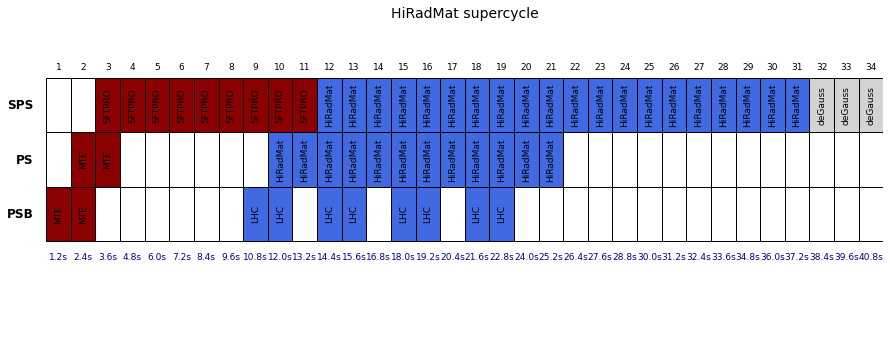

In [22]:
from supercycles.vizualizer import GridVisualizer
plot = GridVisualizer(hiradmat, grid_size=(15, 6), dynamic_grid_size=False).display()

# Some supercycles are not allowed by the SPS RMS limits


In [23]:
not_allowdd_physics_supercycle = Supercycle('SPS', 'Physics',
                                            [SPSCYCLES['SFTPRO']])

Physics supercycle has an average power of: 52.830000000000005 MW exceeds limit of 41.1 MW for SPS


# Having the two HiRadMat cycles

In [26]:
# The original HiRadMat cycle
HiRadMat1 = SPSCYCLES['HiRadMat']
print('Has a length of:', HiRadMat1.length)
print('And an average power of:', HiRadMat1.average_power)

Has a length of: 24.0
And an average power of: 17.52


In [35]:
from supercycles.cycle import Cycle

# The HiRadMat Pilot cycle
SPSCYCLES['HiRadMat pilot'] = Cycle(accelerator='SPS', name='HiRadMat', bps=7,
                                    coupled_cycle=PSCYCLES['LHC pilot'], number_of_injections=1, offset_to_upstream=1,
                                    timing_user='HIRADMT1', average_power=35.1, color='royalblue')

HiRadMat2 = SPSCYCLES['HiRadMat pilot']
print('Has a length of:', HiRadMat2.length)
print('And an average power of:', HiRadMat2.average_power)
print('Note that due to the reduced flat-bottom, the average power is much higher.')

Has a length of: 8.4
And an average power of: 35.1
Note that due to the reduced flat-bottom, the average power is much higher.


HiRadMat Pilot supercycle has an average power of: 52.830000000000005 MW exceeds limit of 41.1 MW for SPS
HiRadMat Pilot supercycle has an average power of: 45.073125000000005 MW exceeds limit of 41.1 MW for SPS


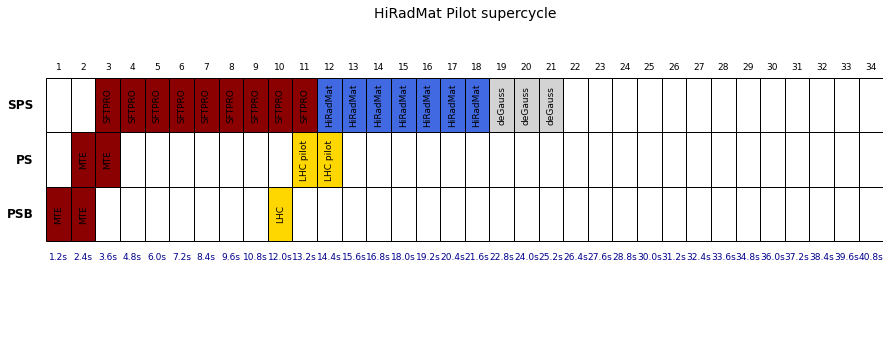

!!!Mind that this supercycle exceeds the SPS RMS current limit!!!


In [36]:
hiradmat = SupercycleGrid(nr_of_slots=34, name='HiRadMat Pilot')
# SPS
hiradmat.add_cycle('SPS', SPSCYCLES['SFTPRO'], 3)
hiradmat.add_cycle('SPS', SPSCYCLES['HiRadMat pilot'])
hiradmat.add_cycle('SPS', SPSCYCLES['deGauss'])
plot = GridVisualizer(hiradmat, grid_size=(15, 6), dynamic_grid_size=False).display()

print('!!!Mind that this supercycle exceeds the SPS RMS current limit!!!')

HiRadMat Pilot supercycle has an average power of: 52.830000000000005 MW exceeds limit of 41.1 MW for SPS


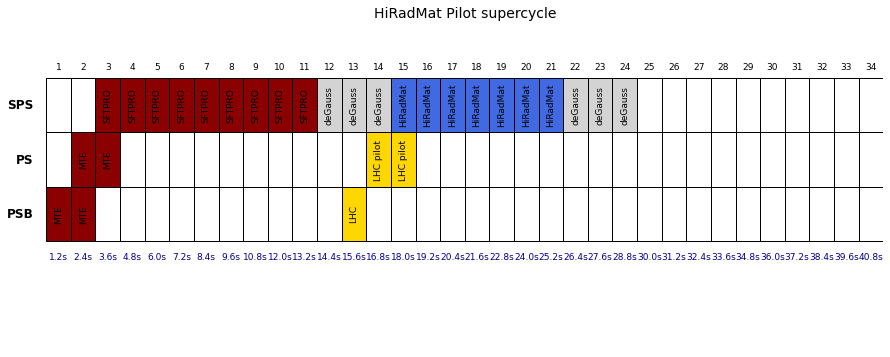

It needs additional deGauss to reduce RMS limits


In [38]:
hiradmat = SupercycleGrid(nr_of_slots=34, name='HiRadMat Pilot')
# SPS
hiradmat.add_cycle('SPS', SPSCYCLES['SFTPRO'], 3)
hiradmat.add_cycle('SPS', SPSCYCLES['deGauss'])
hiradmat.add_cycle('SPS', SPSCYCLES['HiRadMat pilot'])
hiradmat.add_cycle('SPS', SPSCYCLES['deGauss'])
plot = GridVisualizer(hiradmat, grid_size=(15, 6), dynamic_grid_size=False).display()

print('It needs additional deGauss to reduce RMS limits')

# Example of Tirsi

In [6]:
from supercycles.database import SPSCYCLES
from supercycles.supercycle import Supercycle
import matplotlib.pyplot as plt

In [7]:
mysupercycle = Supercycle('SPS', 'mysupercycle_name',
                         [SPSCYCLES['SFTPRO'], SPSCYCLES['HIRADMT1'], SPSCYCLES['deGauss']])

myothersupercycle = Supercycle('SPS', 'mysupercycle_name',
                         [SPSCYCLES['SFTPRO'], SPSCYCLES['HIRADMT2'], SPSCYCLES['deGauss'], SPSCYCLES['SFTPRO'], SPSCYCLES['deGauss']])

In [16]:
mysupercycle.cycles[0].length

10.799999999999999

In [8]:
reprate = mysupercycle.length / mysupercycle.cycle_names.count('HIRADMT1')
print('Repetition rate of mysupercycle is:', reprate, 'seconds')

reprate2 = myothersupercycle.length / myothersupercycle.cycle_names.count('HIRADMT2')
print('Repetition rate of myothersupercycle is:', reprate2, 'seconds')

Repetition rate of mysupercycle is: 22.799999999999997 seconds
Repetition rate of myothersupercycle is: 52.8 seconds


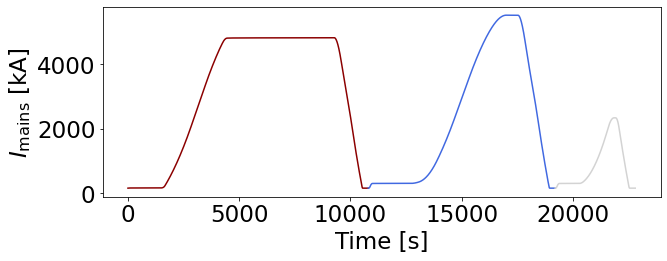

In [10]:
# Plot mysupercycle

f, ax = plt.subplots(1,1,figsize=(10,3.5))
fontsize=23
ax.set_xlabel('Time [s]', fontsize=fontsize)
ax.set_ylabel(r'$I_{\mathrm{mains}}$ [kA]', fontsize=fontsize)
ax.tick_params(axis='both', which='major', labelsize=fontsize)

s0 = 0
for cycle in mysupercycle.cycles:
    ax.plot(s0+cycle.cycle_profile_x, cycle.cycle_profile_y, color=cycle.color)
    s0 += cycle.cycle_profile_x.values[-1]


In [11]:
s0

22800.0

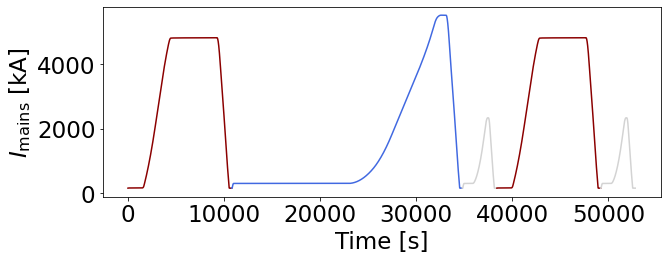

In [17]:
# Plot myothersupercycle

f, ax = plt.subplots(1,1,figsize=(10,3.5))
fontsize=23
ax.set_xlabel('Time [s]', fontsize=fontsize)
ax.set_ylabel(r'$I_{\mathrm{mains}}$ [kA]', fontsize=fontsize)
ax.tick_params(axis='both', which='major', labelsize=fontsize)

s0 = 0
for cycle in myothersupercycle.cycles:
    ax.plot(s0+cycle.cycle_profile_x, cycle.cycle_profile_y, color=cycle.color)
    s0 += cycle.cycle_profile_x.values[-1]
